# Product Sales Exploratory Data Analysis

Clean and explore `data/products.csv` with pandas, Matplotlib, and Seaborn. The last section checks whether a straight line can predict sales.

In [1]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
%matplotlib inline

## Load and inspect the data

In [2]:
path = Path("../data/products.csv")
if not path.exists():
    path = Path("data/products.csv")

products = pd.read_csv(path)
print(products.shape)
display(products.head())
products.info()

(16, 6)


,Product,Category,Price,Rating,Stock,Sales
0,Laptop,Electronics,75000.0,4.5,25.0,120.0
1,Phone,Electronics,30000.0,4.2,80.0,340.0
2,Tablet,Electronics,25000.0,4.0,40.0,95.0
3,Headphones,Electronics,2500.0,NaN,150.0,410.0
4,T-Shirt,Apparel,799.0,4.3,200.0,520.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Product   16 non-null     object 
 1   Category  15 non-null     object 
 2   Price     15 non-null     float64
 3   Rating    15 non-null     float64
 4   Stock     15 non-null     float64
 5   Sales     15 non-null     float64
dtypes: float64(4), object(2)
memory usage: 900.0+ bytes


In [3]:
display(products.isna().sum().to_frame("missing"))
print("Duplicate rows:", products.duplicated().sum())
display(products.describe())

,missing
Product,0
Category,1
Price,1
Rating,1
Stock,1
Sales,1


Duplicate rows: 1


,Price,Rating,Stock,Sales
count,15.000000,15.000000,15.000000,15.000000
mean,10832.600000,4.113333,120.333333,276.000000
std,19902.784568,0.277403,128.681038,241.640228
min,199.000000,3.700000,25.000000,75.000000
25%,1249.000000,3.950000,47.500000,102.500000
50%,2999.000000,4.100000,60.000000,160.000000
75%,7249.000000,4.300000,135.000000,375.000000
max,75000.000000,4.600000,500.000000,890.000000


## Clean the data

Drop the repeated row. Fill blank ratings and sales with the mean, and blank prices and stock with the median. Fill the blank category with the most common category. `revenue` is price times units sold.

In [4]:
cleaned = products.drop_duplicates().copy()

cleaned["Rating"] = cleaned["Rating"].fillna(cleaned["Rating"].mean())
cleaned["Sales"] = cleaned["Sales"].fillna(cleaned["Sales"].mean())
cleaned["Price"] = cleaned["Price"].fillna(cleaned["Price"].median())
cleaned["Stock"] = cleaned["Stock"].fillna(cleaned["Stock"].median())
cleaned["Category"] = cleaned["Category"].fillna(cleaned["Category"].mode()[0])

cleaned["revenue"] = cleaned["Price"] * cleaned["Sales"]

print(cleaned.shape)
cleaned.head()

(15, 7)


,Product,Category,Price,Rating,Stock,Sales,revenue
0,Laptop,Electronics,75000.0,4.500000,25.0,120.0,9000000.0
1,Phone,Electronics,30000.0,4.200000,80.0,340.0,10200000.0
2,Tablet,Electronics,25000.0,4.000000,40.0,95.0,2375000.0
3,Headphones,Electronics,2500.0,4.142857,150.0,410.0,1025000.0
4,T-Shirt,Apparel,799.0,4.300000,200.0,520.0,415480.0


## Univariate exploration

Each histogram is the shape of one column. Price and sales pile up on the low end: a few expensive or high-selling products sit far to the right.

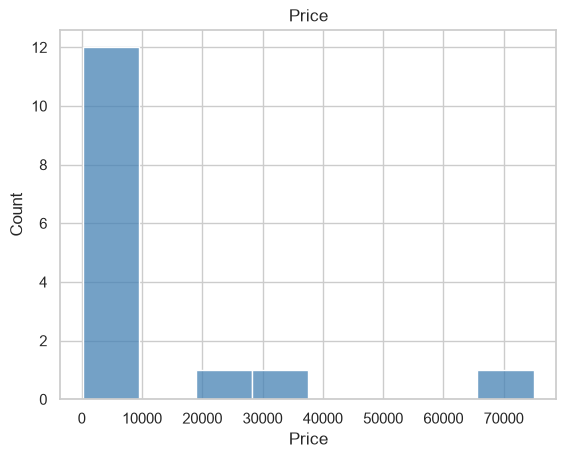

In [5]:
sns.histplot(data=cleaned, x="Price", bins=8, color="steelblue")
plt.title("Price")
plt.show()

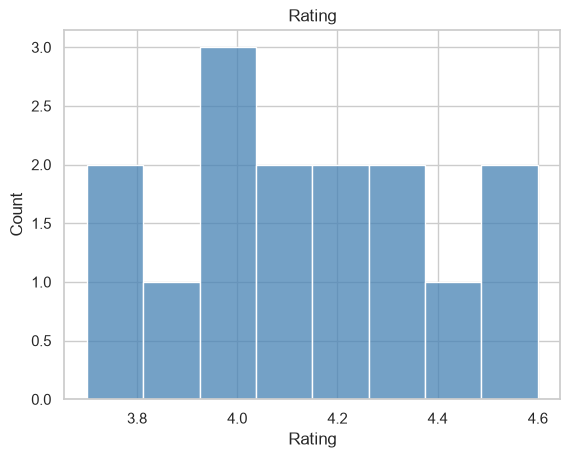

In [6]:
sns.histplot(data=cleaned, x="Rating", bins=8, color="steelblue")
plt.title("Rating")
plt.show()

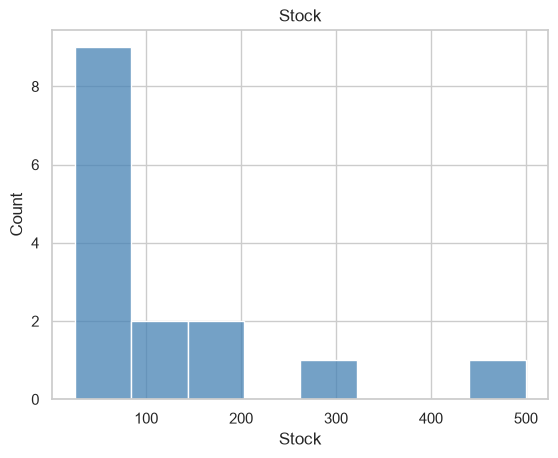

In [7]:
sns.histplot(data=cleaned, x="Stock", bins=8, color="steelblue")
plt.title("Stock")
plt.show()

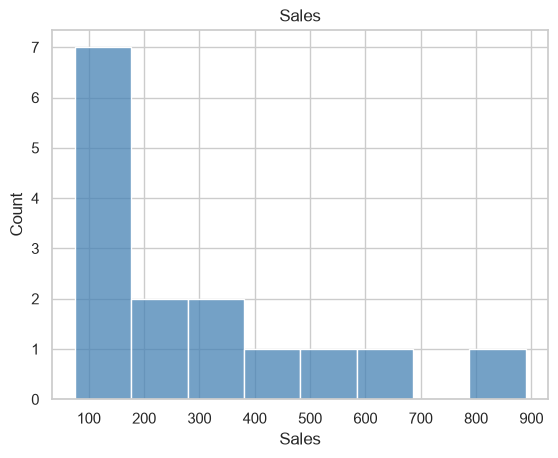

In [8]:
sns.histplot(data=cleaned, x="Sales", bins=8, color="steelblue")
plt.title("Sales")
plt.show()

## Category comparisons

Total units sold differ by category. The price chart shows the range inside each category. Books, Stationery, and Accessories are one product each, so those categories are a single product.

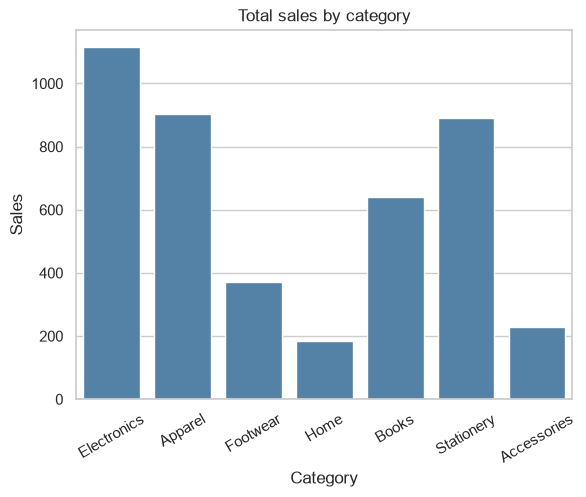

In [9]:
sns.barplot(data=cleaned, x="Category", y="Sales", estimator=sum, errorbar=None, color="steelblue")
plt.title("Total sales by category")
plt.xticks(rotation=30)
plt.show()

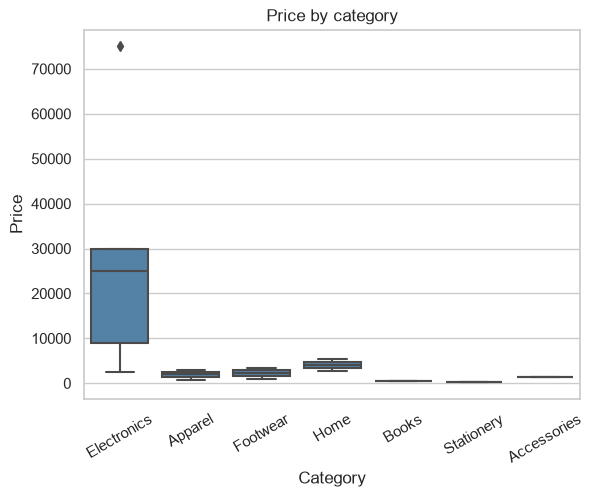

In [10]:
sns.boxplot(data=cleaned, x="Category", y="Price", color="steelblue")
plt.title("Price by category")
plt.xticks(rotation=30)
plt.show()

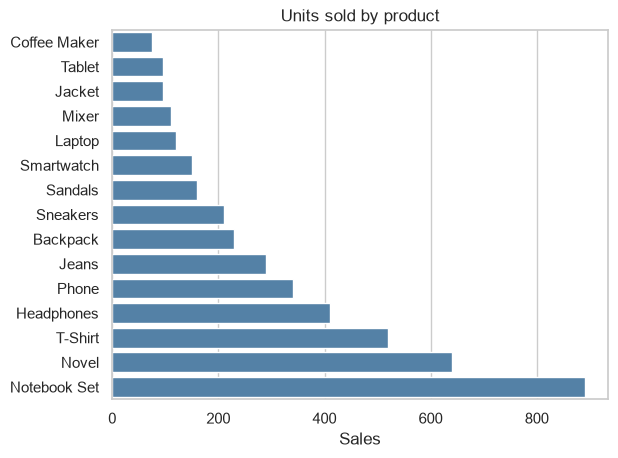

In [11]:
sns.barplot(data=cleaned.sort_values("Sales"), y="Product", x="Sales", color="steelblue")
plt.title("Units sold by product")
plt.ylabel("")
plt.show()

## Relationships

The heatmap is one number per pair. `1` means the columns move together. The line on each scatter is the straight-line fit.

Stock and sales rise together and stay close to the line. Price slopes down only a little, and the points spread around that line.

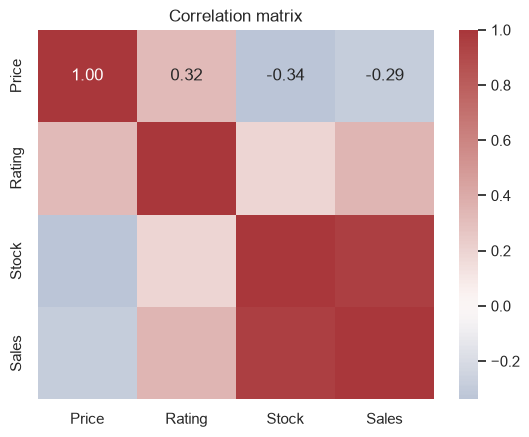

In [12]:
sns.heatmap(cleaned[["Price", "Rating", "Stock", "Sales"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation matrix")
plt.show()

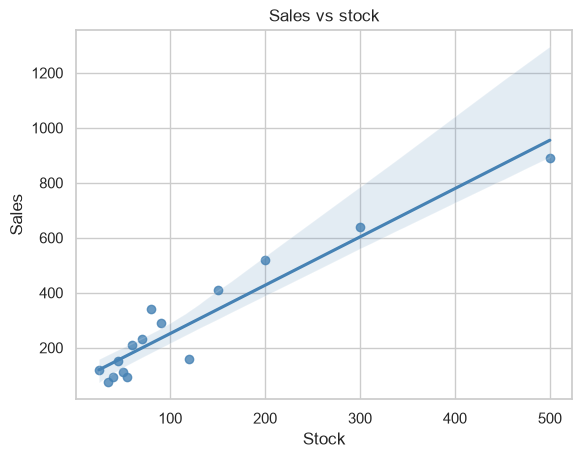

In [13]:
sns.regplot(data=cleaned, x="Stock", y="Sales", color="steelblue")
plt.title("Sales vs stock")
plt.show()

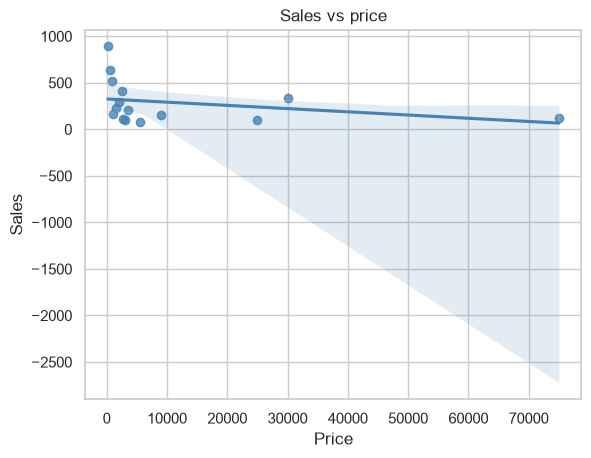

In [14]:
sns.regplot(data=cleaned, x="Price", y="Sales", color="steelblue")
plt.title("Sales vs price")
plt.show()

## Linear regression

The stock chart is a straight line, so sales can be predicted from stock. The model below is that same line, fit on all 15 products. Price is left out because its chart is too scattered for a useful line.

In [15]:
model = LinearRegression().fit(cleaned[["Stock"]], cleaned["Sales"])
print(f"Sales = {model.intercept_:.1f} + {model.coef_[0]:.2f} * Stock")
print(f"R-squared: {model.score(cleaned[['Stock']], cleaned['Sales']):.2f}")

Sales = 75.5 + 1.76 * Stock
R-squared: 0.91


## Insights

- The repeated product row is removed, and the blank price, rating, stock, sales, and category are filled, so all 15 products stay in the charts.
- Notebook Set sells the most units. The cheapest products sit at the top of the sales chart.
- Electronics sells the most units as a category, and its prices spread much higher than the other categories.
- A regression is possible. Sales against stock is a straight line (correlation about 0.95), and the fitted line explains most of the variation in sales.
- Price is a weak downward slope (correlation about -0.29). Ratings stay in a narrow band from 3.7 to 4.6, so rating is a weak guide to sales.
- `revenue` records money taken in. A high price can produce high revenue even when unit sales are modest.